In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

daily = pd.read_csv(
    "../data/processed/rainfall_daily_clean.csv",
    parse_dates=["date"]
)

daily.shape

(1260840, 15)

In [34]:
daily.info()
daily.describe()
daily.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1260840 entries, 0 to 1260839
Data columns (total 15 columns):
 #   Column                Non-Null Count    Dtype         
---  ------                --------------    -----         
 0   State                 1260840 non-null  str           
 1   District              1260840 non-null  str           
 2   date                  1260840 non-null  datetime64[us]
 3   actual_mm             1243768 non-null  float64       
 4   normal_mm             1255919 non-null  float64       
 5   year                  1260840 non-null  int64         
 6   month                 1260840 non-null  int64         
 7   month_name            1260840 non-null  str           
 8   season                1260840 non-null  str           
 9   anomaly_mm            1243767 non-null  float64       
 10  rain_flag             1260840 non-null  int64         
 11  heavy_rain_flag       1260840 non-null  int64         
 12  very_heavy_rain_flag  1260840 non-null  int64        

State                       0
District                    0
date                        0
actual_mm               17072
normal_mm                4921
year                        0
month                       0
month_name                  0
season                      0
anomaly_mm              17073
rain_flag                   0
heavy_rain_flag             0
very_heavy_rain_flag        0
extreme_rain_flag           0
rainfall_intensity          0
dtype: int64

In [35]:
daily["State"].nunique()

36

In [36]:
daily["District"].nunique()

729

In [37]:
daily["date"].min()

Timestamp('2021-01-01 00:00:00')

In [38]:
daily["date"].max()

Timestamp('2026-09-12 00:00:00')

In [39]:
### monthly rainfall analysis ###
monthly = (
    daily.groupby("month")
    .agg(
        avg_rainfall=("actual_mm", "mean"),
        median_rainfall=("actual_mm", "median")
    )
    .reset_index()
)

monthly

,month,avg_rainfall,median_rainfall
0,1,0.531291,0.0
1,2,0.336442,0.0
2,3,0.783389,0.0
3,4,1.292104,0.0
4,5,4.076652,0.0
5,6,6.048089,0.3
6,7,10.037832,2.8
7,8,7.973713,1.7
8,9,6.911217,0.9
9,10,3.222172,0.0


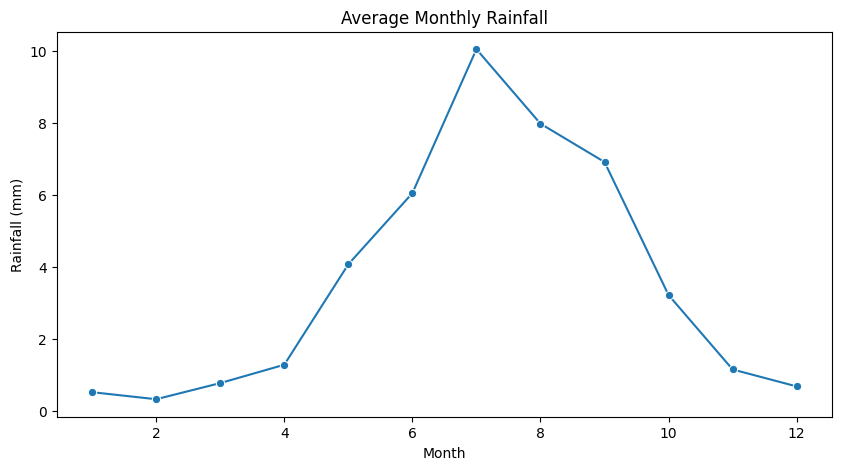

In [40]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=monthly,
    x="month",
    y="avg_rainfall",
    marker="o"
)

plt.title("Average Monthly Rainfall")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.show()

In [41]:
### State-level analysis ###
state_analysis = (
    daily.groupby("State")
    .agg(
        avg_rainfall=("actual_mm", "mean"),
        rainy_days=("rain_flag", "sum"),
        heavy_events=("heavy_rain_flag", "sum"),
        extreme_events=("extreme_rain_flag", "sum")
    )
    .reset_index()
    .sort_values("avg_rainfall", ascending=False)
)

state_analysis.head(10)

,State,avg_rainfall,rainy_days,heavy_events,extreme_events
8,Goa,10.996223,1628,163,3
21,Meghalaya,9.183333,7228,563,55
15,Kerala,8.348076,15594,404,15
31,The Dadra and Nagar Haveli and Daman and Diu,8.121969,1353,159,18
0,Andaman and Nicobar Islands,7.931822,1188,34,0
28,Sikkim,7.528045,3184,69,4
25,Puducherry,6.827993,1915,180,9
2,Arunachal Pradesh,6.176779,12196,353,19
3,Assam,5.924467,21784,619,33
32,Tripura,5.653588,5321,144,4


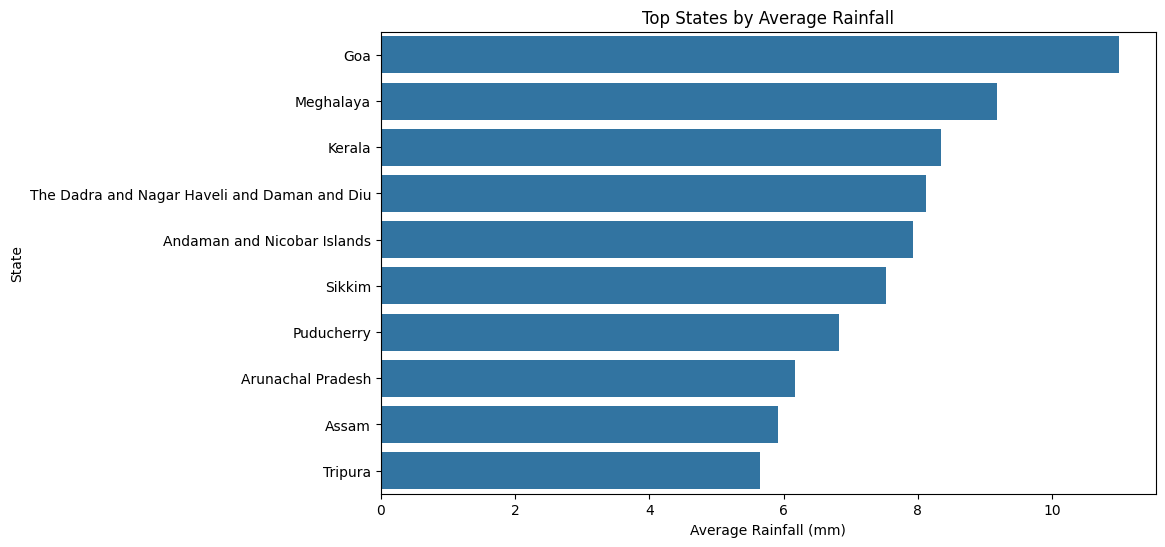

In [42]:
top_states = state_analysis.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_states,
    x="avg_rainfall",
    y="State"
)

plt.title("Top States by Average Rainfall")
plt.xlabel("Average Rainfall (mm)")
plt.ylabel("State")
plt.show()

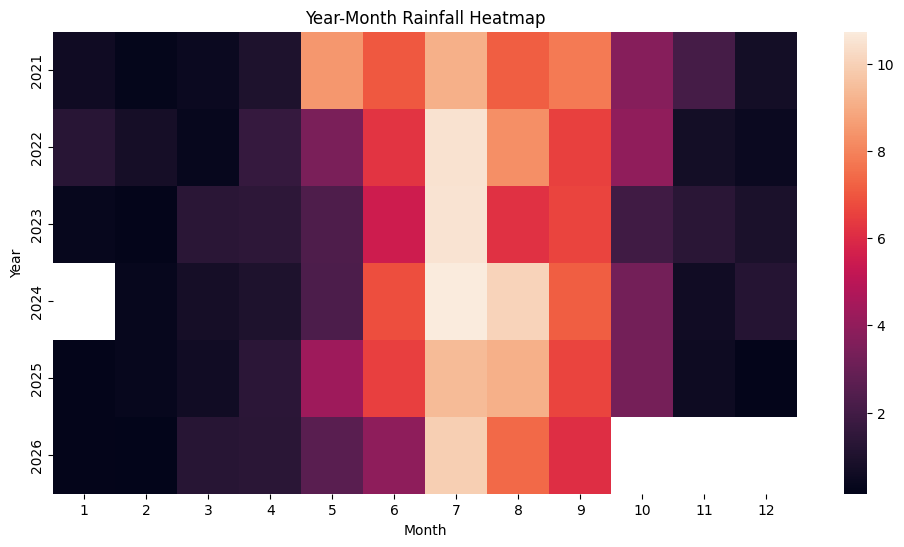

In [43]:
### Year-month analysis ###
year_month = (
    daily.groupby(["year", "month"])["actual_mm"]
    .mean()
    .reset_index()
)

heatmap_data = year_month.pivot(
    index="year",
    columns="month",
    values="actual_mm"
)

plt.figure(figsize=(12,6))

sns.heatmap(
    heatmap_data,
    annot=False
)

plt.title("Year-Month Rainfall Heatmap")
plt.xlabel("Month")
plt.ylabel("Year")
plt.show()

In [ ]:
### Rainfall intensity analysis ###
intensity = (
    daily["rainfall_intensity"]
    .value_counts()
    .reset_index()
)

intensity.columns = ["rainfall_intensity", "count"]

intensity

,rainfall_intensity,count
0,No Rain,817181
1,Light,181833
2,Very Light,154713
3,Moderate,81219
4,Missing,17072
5,Heavy,6888
6,Very Heavy,1556
7,Extremely Heavy,360
8,Unknown,18


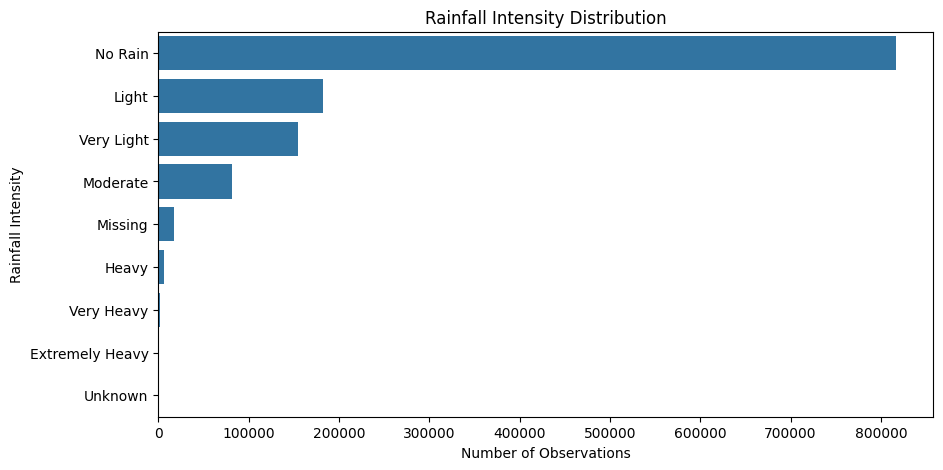

In [47]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=intensity,
    x="count",
    y="rainfall_intensity"
)

plt.title("Rainfall Intensity Distribution")
plt.xlabel("Number of Observations")
plt.ylabel("Rainfall Intensity")
plt.show()

In [49]:
### Extreme rainfall events ###
extreme_events = daily[
    daily["extreme_rain_flag"] == 1
].sort_values(
    "actual_mm",
    ascending=False
)

extreme_events[
    [
        "date",
        "State",
        "District",
        "actual_mm",
        "normal_mm",
        "anomaly_mm"
    ]
].head(20)

,date,State,District,actual_mm,normal_mm,anomaly_mm
818749,2021-05-31,Puducherry,Mahe,1198.80,528.4,670.40
712036,2021-05-31,Meghalaya,East Garo Hills,1175.30,352.0,823.30
94963,2022-07-26,Assam,Jorhat,1169.30,11.4,1157.90
528946,2021-05-31,Kerala,Pathanamthitta,877.30,251.7,625.60
530728,2021-05-31,Kerala,Thiruvananthapuram,804.80,198.4,606.40
521816,2021-05-31,Kerala,Kottayam,780.10,258.5,521.60
511120,2021-05-31,Kerala,Alappuzha,732.70,275.3,457.40
520033,2021-05-31,Kerala,Kollam,721.90,234.0,487.90
1054176,2026-07-23,The Dadra and Nagar Haveli and Daman and Diu,Dadra and Nagar Haveli,700.80,37.3,663.50
512902,2021-05-31,Kerala,Ernakulam,684.00,269.8,414.20


In [51]:
monthly.to_csv(
    "../outputs/day3_monthly_analysis.csv",
    index=False
)

state_analysis.to_csv(
    "../outputs/day3_state_analysis.csv",
    index=False
)

extreme_events.to_csv(
    "../outputs/day3_extreme_events.csv",
    index=False
)